In [1]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import numpy as np
from scipy.stats import pointbiserialr
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import optuna

import warnings
warnings.filterwarnings('ignore')

c:\Users\Louis Bernal\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Data Exploration

In [2]:
# collect dataset
adult = fetch_ucirepo(id=2) 

# table format
independent = adult.data.features 
depdendent = adult.data.targets 
  
df = pd.concat([independent, depdendent], axis=1)
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States,<=50K.
48838,64,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40,United-States,<=50K.
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States,<=50K.
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States,<=50K.


In [3]:
df.describe(include='all')

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
count,48842.000000,47879,4.884200e+04,48842,48842.000000,48842,47876,48842,48842,48842,48842.000000,48842.000000,48842.000000,48568,48842
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,4
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,33906,NaN,15784,NaN,22379,6172,19716,41762,32650,NaN,NaN,NaN,43832,24720
mean,38.643585,NaN,1.896641e+05,NaN,10.078089,NaN,NaN,NaN,NaN,NaN,1079.067626,87.502314,40.422382,NaN,NaN
std,13.710510,NaN,1.056040e+05,NaN,2.570973,NaN,NaN,NaN,NaN,NaN,7452.019058,403.004552,12.391444,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.175505e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.781445e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.376420e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [5]:
df.isnull().sum()

age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(29)

In [7]:
# scan outlier values in string columns

for col in df.select_dtypes('object'):
    print(f'\n',col, df[col].unique())


 workclass ['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'Local-gov' '?'
 'Self-emp-inc' 'Without-pay' 'Never-worked' nan]

 education ['Bachelors' 'HS-grad' '11th' 'Masters' '9th' 'Some-college' 'Assoc-acdm'
 'Assoc-voc' '7th-8th' 'Doctorate' 'Prof-school' '5th-6th' '10th'
 '1st-4th' 'Preschool' '12th']

 marital-status ['Never-married' 'Married-civ-spouse' 'Divorced' 'Married-spouse-absent'
 'Separated' 'Married-AF-spouse' 'Widowed']

 occupation ['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' '?'
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv' nan]

 relationship ['Not-in-family' 'Husband' 'Wife' 'Own-child' 'Unmarried' 'Other-relative']

 race ['White' 'Black' 'Asian-Pac-Islander' 'Amer-Indian-Eskimo' 'Other']

 sex ['Male' 'Female']

 native-country ['United-States' 'Cuba' 'Jamaica' 'India' '?' 'Mexico' 'South'
 'Puerto-Rico' 'Hondu

#### Data Cleaning

In [8]:
df = df.fillna('undefined')

In [9]:
df['income'] = df['income'].str.replace('.', '', regex = False).str.strip()

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48842 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


#### Feature Engineering

In [11]:
df['capital-difference'] = df['capital-gain'] - df['capital-loss']

In [12]:
df['age_group'] = pd.cut(df['age'], bins = [16, 25, 35, 45, 65], labels = ['young','adult', 'middle_age', 'senior'])

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   age                 48842 non-null  int64   
 1   workclass           48842 non-null  object  
 2   fnlwgt              48842 non-null  int64   
 3   education           48842 non-null  object  
 4   education-num       48842 non-null  int64   
 5   marital-status      48842 non-null  object  
 6   occupation          48842 non-null  object  
 7   relationship        48842 non-null  object  
 8   race                48842 non-null  object  
 9   sex                 48842 non-null  object  
 10  capital-gain        48842 non-null  int64   
 11  capital-loss        48842 non-null  int64   
 12  hours-per-week      48842 non-null  int64   
 13  native-country      48842 non-null  object  
 14  income              48842 non-null  object  
 15  capital-difference  48842 non-null  

#### Data Visualization

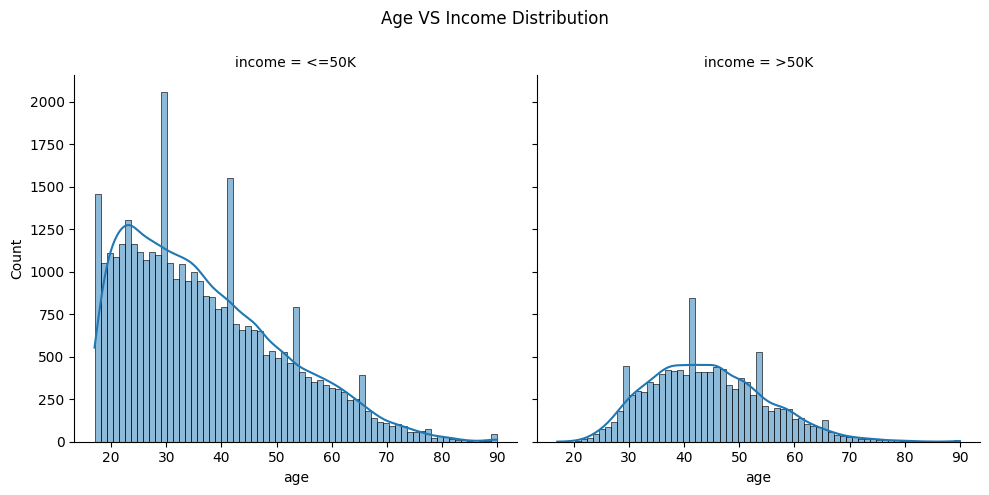

In [14]:
# Age vs Income Distribution

p = sns.displot(data=df, x ='age', col = 'income', kde = True)
p.fig.suptitle('Age VS Income Distribution')
p.fig.subplots_adjust(top=0.85)

Text(0.5, 1.0, 'Income by Education Level')

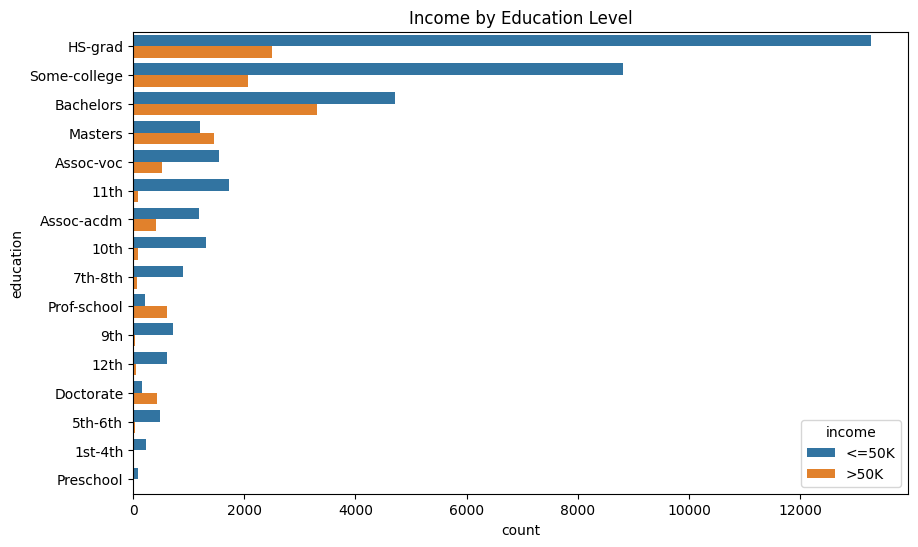

In [15]:
education_order = df['education'].value_counts().index
plt.figure(figsize = (10, 6))
sns.countplot(data= df, y = 'education', hue = 'income', order = education_order)
plt.title('Income by Education Level')

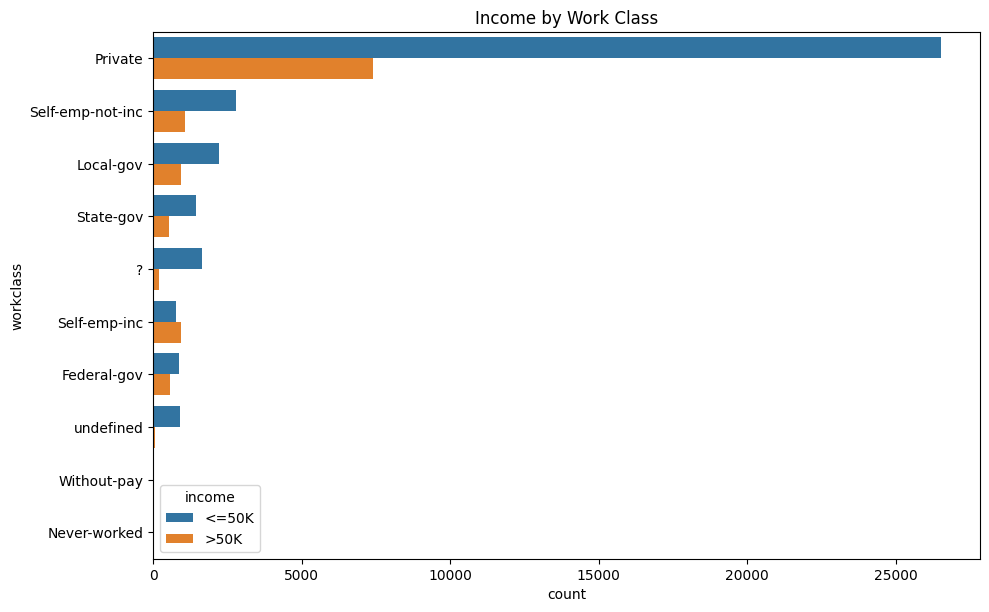

In [16]:
order = df['workclass'].value_counts().index

plt.figure(figsize = (10, 6))
sns.countplot(data= df, y = 'workclass', hue = 'income', order = order)
plt.tight_layout() 
plt.title('Income by Work Class')      
plt.show()

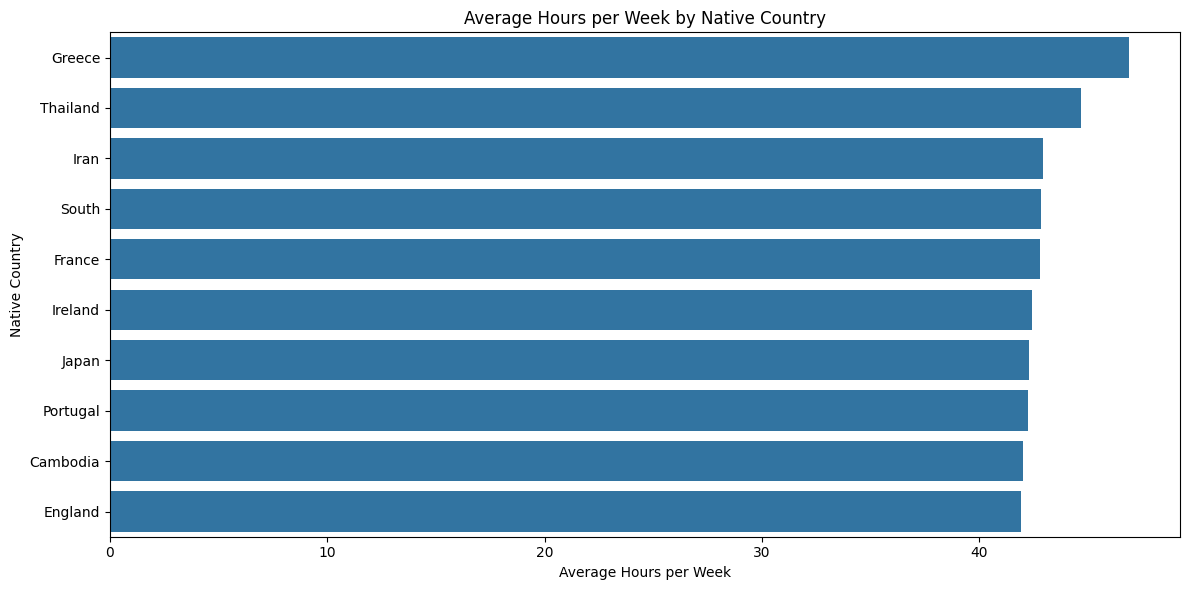

In [17]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x='hours-per-week',
    y='native-country',
    estimator='mean',
    errorbar=None,
    order=df.groupby('native-country')['hours-per-week'].mean().sort_values(ascending=False).head(10).index
)
plt.title('Average Hours per Week by Native Country')
plt.xlabel('Average Hours per Week')
plt.ylabel('Native Country')
plt.tight_layout()
plt.show()


#### Outlier Detection


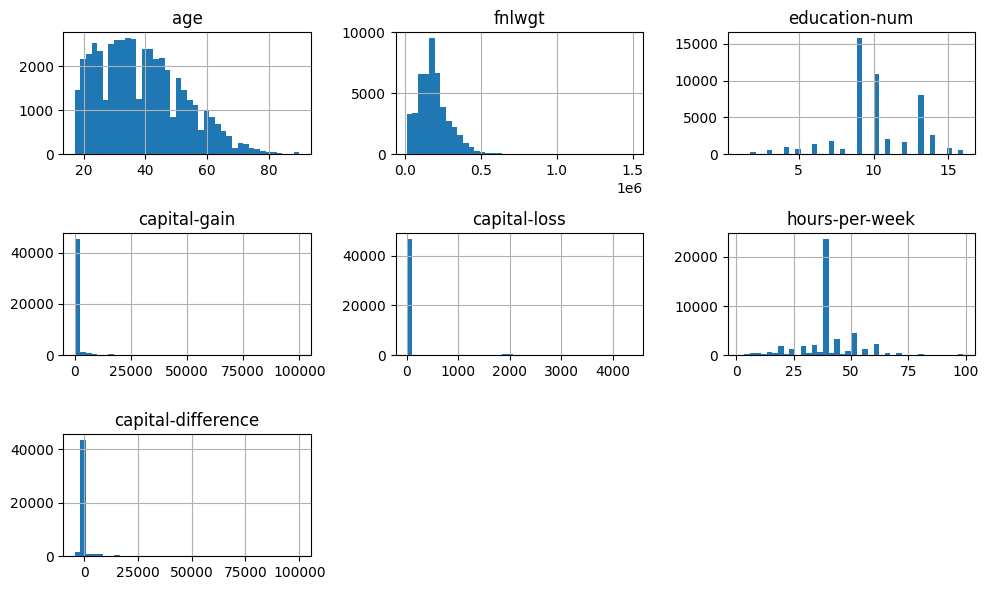

In [18]:
df.hist(bins = 40, figsize = (10, 6))
plt.tight_layout()

Text(0.5, 1.0, 'Correlation Matrix')

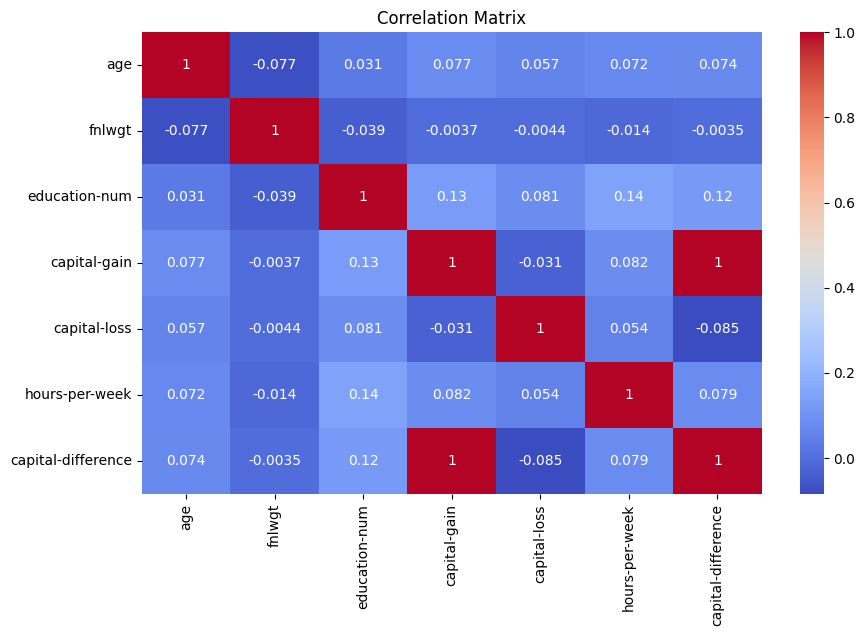

In [19]:
num_df = df.select_dtypes(include = ['int64', 'float64'])
df_corr = num_df.corr()

plt.figure(figsize = (10, 6))
sns.heatmap(df_corr, annot = True, cmap= 'coolwarm')
plt.title('Correlation Matrix')

([0, 1, 2, 3, 4, 5, 6],
 [Text(0, 0, 'age'),
  Text(1, 0, 'fnlwgt'),
  Text(2, 0, 'education-num'),
  Text(3, 0, 'capital-gain'),
  Text(4, 0, 'capital-loss'),
  Text(5, 0, 'hours-per-week'),
  Text(6, 0, 'capital-difference')])

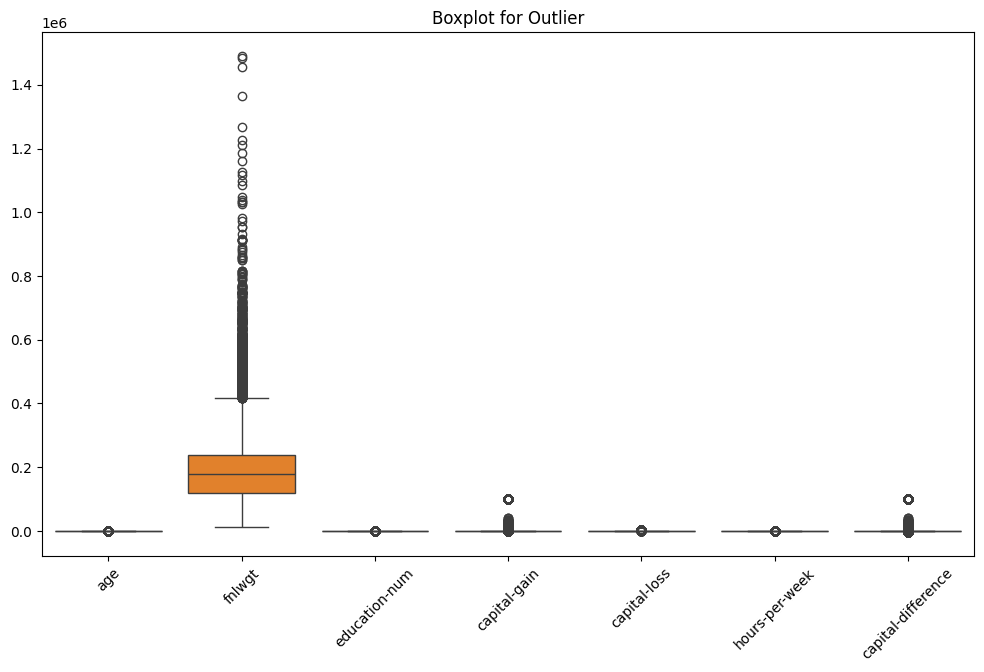

In [20]:
plt.figure(figsize = (10, 6))
sns.boxplot(data=df)
plt.title('Boxplot for Outlier')
plt.tight_layout()
plt.xticks(rotation=45)

In [21]:
# showcase correlation between numeric features and string target variable

df['y_encoded'] = df['income'].map({'<=50K': 0, '>50K': 1})

# Select numeric columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Compute correlation
for col in num_cols:
    corr, p_value = pointbiserialr(df[col], df['y_encoded'])
    print(f"{col}: correlation = {corr:.3f}, p-value = {p_value:.3f}")


age: correlation = 0.230, p-value = 0.000
fnlwgt: correlation = -0.006, p-value = 0.161
education-num: correlation = 0.333, p-value = 0.000
capital-gain: correlation = 0.223, p-value = 0.000
capital-loss: correlation = 0.148, p-value = 0.000
hours-per-week: correlation = 0.228, p-value = 0.000
capital-difference: correlation = 0.214, p-value = 0.000
y_encoded: correlation = 1.000, p-value = 0.000


In [22]:
# inspect target variable distribution

df['income'].value_counts()

income
<=50K    37155
>50K     11687
Name: count, dtype: int64

#### Data Preprocessing

In [23]:
df.drop(['fnlwgt'], axis = 1, inplace = True)

In [24]:
df_object = df.select_dtypes(exclude=['int64', 'float64']).columns

for col in df_object:
    df[col] = LabelEncoder().fit_transform(df[col])

In [25]:
x = df.drop(['income', 'y_encoded'], axis = 1)
y = df['income']

In [26]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.05, random_state = 42)

In [27]:
rs = RobustScaler()
x_train = rs.fit_transform(x_train)
x_test = rs.transform(x_test)

#### Data Modeling

In [28]:
lg = LogisticRegression(class_weight= 'balanced')
lg.fit(x_train, y_train)

y_pred = lg.predict(x_test)
print('Logistic Regression:\n')
print(classification_report(y_test, y_pred))


Logistic Regression:

              precision    recall  f1-score   support

           0       0.91      0.77      0.83      1869
           1       0.50      0.76      0.60       574

    accuracy                           0.76      2443
   macro avg       0.70      0.76      0.72      2443
weighted avg       0.81      0.76      0.78      2443



In [29]:
nb = GaussianNB()
nb.fit(x_train, y_train)

y_pred = nb.predict(x_test)
print('Naive bayes:\n')
print(classification_report(y_test, y_pred))

Naive bayes:

              precision    recall  f1-score   support

           0       0.81      0.96      0.88      1869
           1       0.67      0.28      0.40       574

    accuracy                           0.80      2443
   macro avg       0.74      0.62      0.64      2443
weighted avg       0.78      0.80      0.77      2443



In [30]:
knn = KNeighborsClassifier()
knn.fit(x_train, y_train)

y_pred = knn.predict(x_test)
print('KNN:\n')
print(classification_report(y_test, y_pred))

KNN:

              precision    recall  f1-score   support

           0       0.88      0.92      0.90      1869
           1       0.69      0.59      0.64       574

    accuracy                           0.84      2443
   macro avg       0.78      0.75      0.77      2443
weighted avg       0.83      0.84      0.84      2443



In [31]:
rf = RandomForestClassifier(class_weight= 'balanced')
rf.fit(x_train, y_train)
y_pred = rf.predict(x_test)
print('Random Forest Classifier:\n')    
print(classification_report(y_test, y_pred))

Random Forest Classifier:

              precision    recall  f1-score   support

           0       0.89      0.91      0.90      1869
           1       0.68      0.62      0.65       574

    accuracy                           0.84      2443
   macro avg       0.78      0.77      0.77      2443
weighted avg       0.84      0.84      0.84      2443



In [32]:
xg =XGBClassifier()
xg.fit(x_train, y_train)
y_pred = xg.predict(x_test)
print('XGBClassifier: \n')
print(classification_report(y_test, y_pred))

XGBClassifier: 

              precision    recall  f1-score   support

           0       0.89      0.94      0.92      1869
           1       0.77      0.63      0.69       574

    accuracy                           0.87      2443
   macro avg       0.83      0.79      0.80      2443
weighted avg       0.86      0.87      0.86      2443



#### Hyperparameter Tuning

In [33]:
xgb_params = {
    'objective' : ['binary:logistic'],
    'eval_metric' : ['logloss'],
    'eta' : [0.09],
    'max_depth' : [20, 22],
    'min_child_weight' : [1],
    'subsample' : [1],
    'colsample_bytree' : [1.0],
}

xgb_grid = GridSearchCV(XGBClassifier(), xgb_params, cv = 10, n_jobs = -1)
xgb_grid.fit(x_train, y_train)

xgb = xgb_grid.best_estimator_
print('Best Parameters:', xgb_grid.best_params_)

Best Parameters: {'colsample_bytree': 1.0, 'eta': 0.09, 'eval_metric': 'logloss', 'max_depth': 20, 'min_child_weight': 1, 'objective': 'binary:logistic', 'subsample': 1}


In [34]:
xgb_training_score = cross_val_score(xgb, x_train, y_train, cv = 5)
print(f'{xgb.__class__.__name__} Tuned Training Score: {xgb_training_score.mean()* 100, 2}')

XGBClassifier Tuned Training Score: (np.float64(86.52342028347289), 2)


In [35]:
y_pred = xgb.predict(x_test)
print('Tuned XGBoost Report: \n', classification_report(y_test, y_pred))

Tuned XGBoost Report: 
               precision    recall  f1-score   support

           0       0.89      0.93      0.91      1869
           1       0.73      0.62      0.67       574

    accuracy                           0.86      2443
   macro avg       0.81      0.78      0.79      2443
weighted avg       0.85      0.86      0.85      2443



Text(0.5, 1.0, 'Tuned XGboost Confusion Matrix')

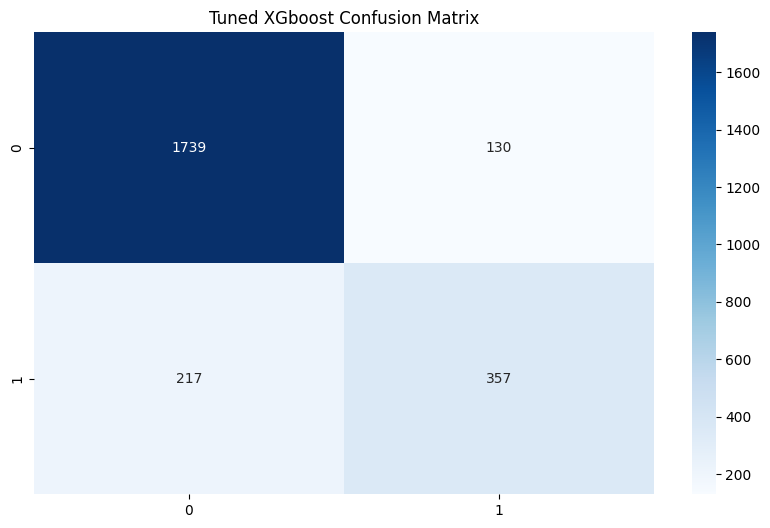

In [36]:
cm =  confusion_matrix(y_test, y_pred)

plt.figure(figsize = (10, 6))
sns.heatmap(cm , annot=True, cmap = 'Blues', fmt = 'g')
plt.title('Tuned XGboost Confusion Matrix')

#### Optuna + XGboost Tuning

In [37]:
def objective(trial):
    params = {
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'eta': trial.suggest_float('eta', 0.01, 0.2),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'lambda': trial.suggest_float('lambda', 1, 10),
        'alpha': trial.suggest_float('alpha', 0, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1, 5),
        'n_estimators': trial.suggest_int('n_estimators', 100, 500)
    }

    # Train model
    model = XGBClassifier(**params, n_jobs=-1, random_state=42)
    model.fit(x_train, y_train)

    # Evaluate on validation set
    y_pred = model.predict(x_test)
    accuracy = accuracy_score(y_test, y_pred)
    return accuracy

In [38]:
# Create Optuna study
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=200) 

[I 2025-10-25 20:35:07,314] A new study created in memory with name: no-name-1cc7bec9-4664-4cc4-9fbb-45d07f5ded82
[I 2025-10-25 20:35:07,890] Trial 0 finished with value: 0.809250920998772 and parameters: {'eta': 0.1849189319317636, 'max_depth': 8, 'min_child_weight': 3, 'subsample': 0.824845141055149, 'colsample_bytree': 0.9713383005594547, 'gamma': 0.05550928936695787, 'lambda': 2.572344203888785, 'alpha': 6.273914650888008, 'scale_pos_weight': 3.6402792288065013, 'n_estimators': 153}. Best is trial 0 with value: 0.809250920998772.
[I 2025-10-25 20:35:09,277] Trial 1 finished with value: 0.7973802701596397 and parameters: {'eta': 0.06680948834846555, 'max_depth': 7, 'min_child_weight': 10, 'subsample': 0.6062517325474992, 'colsample_bytree': 0.6118621322714362, 'gamma': 2.2669167405071744, 'lambda': 4.993305401954004, 'alpha': 2.4657318349607382, 'scale_pos_weight': 4.330243351787917, 'n_estimators': 429}. Best is trial 0 with value: 0.809250920998772.
[I 2025-10-25 20:35:09,720] Tri

In [39]:
# Show best results
print("Best Trial:\n")
print(f"  Accuracy: {study.best_value:.4f}")
print("  Best Params:", study.best_params)

Best Trial:

  Accuracy: 0.8707
  Best Params: {'eta': 0.08458433189100359, 'max_depth': 16, 'min_child_weight': 8, 'subsample': 0.8056015163456514, 'colsample_bytree': 0.9409054874093012, 'gamma': 2.7537332326052937, 'lambda': 6.6796255617504, 'alpha': 0.2834614989205276, 'scale_pos_weight': 1.3913602172800175, 'n_estimators': 290}


In [40]:
# Train final model using best parameters
best_params = study.best_params
xgb_best = XGBClassifier(**best_params, random_state=42)
xgb_best.fit(x_train, y_train)

# Predict
y_pred = xgb_best.predict(x_test)

In [41]:

# Classification Report
print("Optuna + XGBoost Classification Report:\n", classification_report(y_test, y_pred))

Optuna + XGBoost Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.92      0.92      1869
           1       0.73      0.72      0.72       574

    accuracy                           0.87      2443
   macro avg       0.82      0.82      0.82      2443
weighted avg       0.87      0.87      0.87      2443



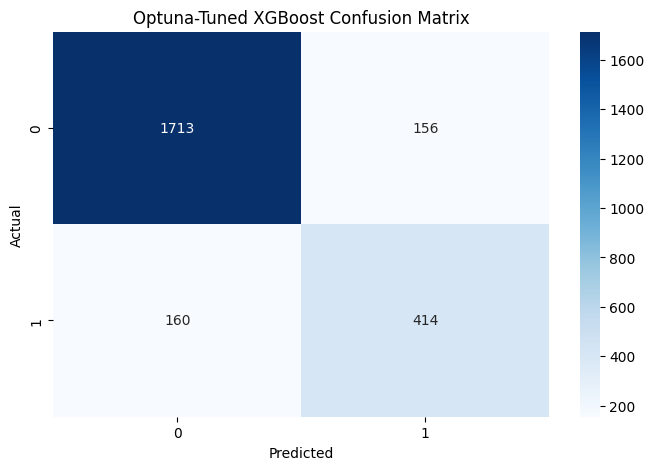

In [42]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 5))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues')
plt.title('Optuna-Tuned XGBoost Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [43]:
cv_score = cross_val_score(xgb_best, x_train, y_train, cv=5)
print(f"Optuna + XGboost Cross-Validation Accuracy: {cv_score.mean():.4f}")

Optuna + XGboost Cross-Validation Accuracy: 0.8695
